# Première inspection d’un dataset

**Projet / problématique commune :** Projet compagnon immo

**Dataset :** taux_interet_annuels_crédits_immo.csv


**Contributeurs :** Gabrielle RICHERT · **Date :** 13.10.2026

**Version des données :** …

**Référence du fichier / source :** …

## Mode d’emploi collectif

Dupliquer ce notebook pour chaque dataset. Suivre les étapes dans l’ordre et revenir sur une conclusion si une observation ultérieure la remet en cause. Les cellules de code sont vides : vous choisissez les opérations, et pouvez ajouter des cellules.

- Renseigner « non applicable » ou « information inconnue » plutôt que forcer une réponse.
- Conserver les résultats utiles et les figures près de leur commentaire.
- Distinguer observations, hypothèses et décisions ; des points peuvent rester à approfondir.
- Rédiger un seul bilan par grande étape, réutilisable dans le rapport de recherche.
- Faire relire les conclusions par un autre membre du groupe.

**Référence du notebook / script destiné à la remise séparée du code :** 

## 1. Situer la source et ouvrir les données

**À faire dans l’ordre :**
1. Identifier la source et consulter la documentation.
2. Préciser la collecte et le périmètre annoncés.
3. Charger les données et vérifier leur lecture.

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine |Banque de France FR2 | aucun fichier de métadonnées associé|
| Finalité initiale | | |
| Mode de collecte | aucune information| |
| Extraction / mise à jour |aucune information | |
| Documentation / licence | aucune information| |
| Population / objets annoncés |France | |
| Période / territoire, si pertinents |de décembre 98 jusqu'à août 2026| |

In [1]:
cd /home/ubuntu/projet_compagnon/data

/home/ubuntu/projet_compagnon/data


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

taux = pd.read_csv("taux_interet_annuels_credits_immo.csv", sep=";")
taux.drop(inplace=True, index=[0,1,2,3,4], axis=0)
taux=taux.reset_index(drop=True)
taux=taux.rename(columns={taux.columns[0] : 'date', taux.columns[1] : 'taux'})

In [4]:
taux.head()

,date,taux
0,2026-08-31,"3,21"
1,2026-07-31,"3,18"
2,2026-06-30,"3,17"
3,2026-05-31,"3,11"
4,2026-04-30,"3,12"


In [5]:
# La colonne date est du texte ("2020-01") : on la convertit en vraie date
date = pd.to_datetime(taux["date"])

# Date de la plus ancienne et de la plus récente annonce
print("Du", date.min(), "au", date.max())

# Nombre d'annonces par année, triées dans l'ordre chronologique
print(date.dt.year.value_counts().sort_index())

Du 1998-12-31 00:00:00 au 2026-08-31 00:00:00
date
1998     1
1999    12
2000    12
2001    12
2002    12
2003    12
2004    12
2005    12
2006    12
2007    12
2008    12
2009    12
2010    12
2011    12
2012    12
2013    12
2014    12
2015    12
2016    12
2017    12
2018    12
2019    12
2020    12
2021    12
2022    12
2023    12
2024    12
2025    12
2026     8
Name: count, dtype: int64


## 2. Comprendre la structure et une ligne

**À faire dans l’ordre :**
1. Examiner les dimensions, les colonnes et quelques observations.
2. Décrire ce que représente une ligne.
3. Identifier les clés possibles et examiner les répétitions.
4. Contrôler les doublons exacts et distinguer répétitions normales et doublons possibles.

| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 333 lignes × 2 colonnes |
| Contenu général, en une phrase | taux des crédits immobiliers par mois de décembre 98 à août 2026|
| Unité d’observation | un taux en % mensuel|
| Identifiants / clés possibles | pas d'identifiant/références par date |
| Une ou plusieurs lignes par objet ? Pourquoi ? | non applicable, il n'y a qu'un taux par mois même si le taux peut être identique pendant plusieurs mois |
| Doublons exacts : nombre / proportion | 0 (0 %)|
| Répétitions métier : règle examinée / résultat | non applicable |

In [6]:


print(taux.shape) 
taux.info() 

# On regarde s'il y a des doublons exacts dans le dataset sans prendre en compte l'Index
taux.duplicated().sum() 


(333, 2)
<class 'pandas.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   date    333 non-null    str  
 1   taux    333 non-null    str  
dtypes: str(2)
memory usage: 5.3 KB


np.int64(0)

**Constat :**

Le jeu `taux` contient un taux de crédit immobilier moyen par mois en %.

**Impact projet :**

Utilisation de l'évolution des taux au cours du temps pour voir leur impact sur le prix de vente/achat des biens.

**Action envisagée :**

Attention à la colonne `date`, au départ la date n'était que mensuelle (exemble janvier 2026) mais avec la fonction to_datetime elle passe en JJ/MM/AAA.

**Incertitudes / limites, si nécessaire :**

Fichier très simple, uniquement en supplément et pas en analyse seule.

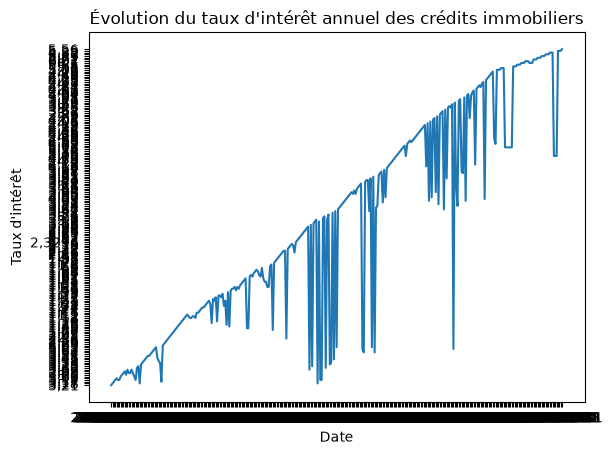

In [ ]:
import datetime
annees_graphe=[datetime.date(1998,12,1), datetime.date(2000,1,1), datetime.date(2010,1,1), datetime.date(2020,1,1), datetime.date(2026,8,31)]
libelles=['1998','2000', '2010', '2020', '2026']

plt.plot(taux["date"], taux["taux"])
plt.xlabel("Date")
plt.xticks(annees_graphe, libelles)
plt.ylabel("Taux d'intérêt")
plt.locator_params(axis='y', nbins=10)
plt.title("Évolution du taux d'intérêt annuel des crédits immobiliers")
plt.show()